# ParekrafMind: Smart Tourism Investment Intelligence for Creative Economy Growth

- **Mata Kuliah:** Data Mining 2
- **Tema:** Creative Industry
- **Kelompok:** Dharma Mudita, Arga Bayu Ramadhan, Yolla Fiorenza
- **Dataset:** `Nilai_Investasi_PMDN_sektor_pariwisata_Tahun_2025.csv` (1.471 data, 38 provinsi)


## 1. Import Library dan Load Dataset

In [1]:
# Jika dijalankan di Google Colab dan mlxtend belum terpasang:
# !pip install -q mlxtend

import os
import time
import json
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 110

csv_file = 'Nilai_Investasi_PMDN_sektor_pariwisata_Tahun_2025.csv'

if not os.path.exists(csv_file):
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_file = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(f'File {csv_file} tidak ditemukan di direktori kerja.')

df_raw = pd.read_csv(csv_file)
print(f'Ukuran dataset: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom')
df_raw.head()


Ukuran dataset: 1471 baris, 6 kolom


,Tahun,Triwulan,Provinsi,Kab/Kot,DPP,Nilai Investasi Rp. Juta
0,2025,2,Sulawesi Tenggara,Kabupaten Wakatobi,Wakatobi,0.0
1,2025,3,Sulawesi Tenggara,Kabupaten Wakatobi,Wakatobi,0.0
2,2025,1,Papua Barat Daya,Kabupaten Raja Ampat,Raja Ampat,35.0
3,2025,2,Papua Barat,Kabupaten Raja Ampat,Raja Ampat,0.0
4,2025,2,Papua Barat Daya,Kabupaten Raja Ampat,Raja Ampat,100.0


## 2. Eksplorasi Data (EDA)

Pengecekan tipe data, statistik deskriptif nilai investasi, serta sebaran total investasi berdasarkan triwulan dan status Destinasi Pariwisata Prioritas (DPP).

Jumlah provinsi unik : 38
Data kawasan DPP     : 134
Data investasi nol   : 194


,count,mean,std,min,25%,50%,75%,max
Nilai Investasi Rp. Juta,1471.0,35867.768292,149055.003985,0.0,29.929595,828.079801,8508.753925,3.225614e+06


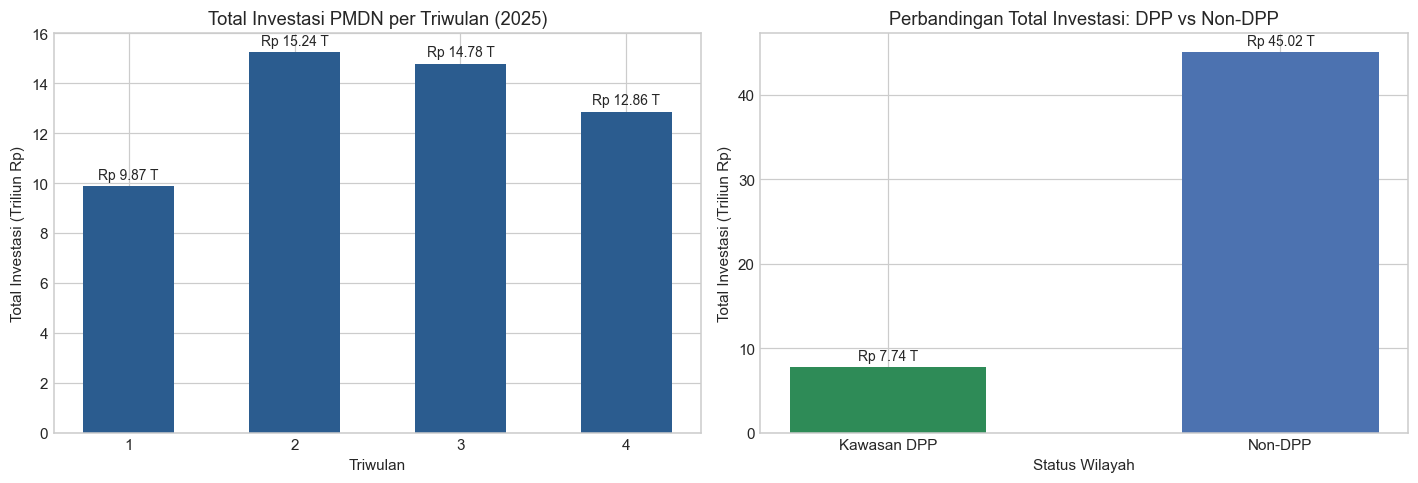

In [2]:
df = df_raw.copy()
df['Nilai Investasi Rp. Juta'] = pd.to_numeric(df['Nilai Investasi Rp. Juta'], errors='coerce').fillna(0.0)

for col in ['Provinsi', 'Kab/Kot', 'DPP']:
    df[col] = df[col].fillna('').astype(str).str.strip()

print('Jumlah provinsi unik :', df['Provinsi'].nunique())
print('Data kawasan DPP     :', (df['DPP'] != '').sum())
print('Data investasi nol   :', (df['Nilai Investasi Rp. Juta'] == 0).sum())
display(df['Nilai Investasi Rp. Juta'].describe().to_frame().T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

tw_sum = df.groupby('Triwulan')['Nilai Investasi Rp. Juta'].sum() / 1e6
bars1 = axes[0].bar(tw_sum.index.astype(str), tw_sum.values, color='#2b5c8f', width=0.55)
axes[0].set_title('Total Investasi PMDN per Triwulan (2025)')
axes[0].set_xlabel('Triwulan')
axes[0].set_ylabel('Total Investasi (Triliun Rp)')
for b in bars1:
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.3, f'Rp {b.get_height():.2f} T', ha='center', fontsize=9)

status_series = df['DPP'].apply(lambda x: 'Kawasan DPP' if x != '' else 'Non-DPP')
dpp_sum = df.groupby(status_series)['Nilai Investasi Rp. Juta'].sum() / 1e6
bars2 = axes[1].bar(dpp_sum.index, dpp_sum.values, color=['#2e8b57', '#4c72b0'], width=0.5)
axes[1].set_title('Perbandingan Total Investasi: DPP vs Non-DPP')
axes[1].set_xlabel('Status Wilayah')
axes[1].set_ylabel('Total Investasi (Triliun Rp)')
for b in bars2:
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, f'Rp {b.get_height():.2f} T', ha='center', fontsize=9)

plt.tight_layout()
plt.show()


## 3. Preprocessing dan One-Hot Encoding

Mengelompokkan 38 provinsi ke dalam 6 zona kepulauan dan mengubah nilai investasi numerik ke 4 kategori skala usaha agar siap diolah dengan aturan asosiasi.

In [3]:
pulau_map = {
    'Aceh': 'Sumatera', 'Sumatera Utara': 'Sumatera', 'Sumatera Barat': 'Sumatera', 'Riau': 'Sumatera',
    'Kepulauan Riau': 'Sumatera', 'Jambi': 'Sumatera', 'Sumatera Selatan': 'Sumatera', 'Bengkulu': 'Sumatera',
    'Lampung': 'Sumatera', 'Kepulauan Bangka Belitung': 'Sumatera',
    'Daerah Khusus Ibukota Jakarta': 'Jawa', 'DKI Jakarta': 'Jawa', 'Jawa Barat': 'Jawa', 'Jawa Tengah': 'Jawa',
    'Daerah Istimewa Yogyakarta': 'Jawa', 'DI Yogyakarta': 'Jawa', 'Jawa Timur': 'Jawa', 'Banten': 'Jawa',
    'Bali': 'Bali_Nusra', 'Nusa Tenggara Barat': 'Bali_Nusra', 'Nusa Tenggara Timur': 'Bali_Nusra',
    'Kalimantan Barat': 'Kalimantan', 'Kalimantan Tengah': 'Kalimantan', 'Kalimantan Selatan': 'Kalimantan',
    'Kalimantan Timur': 'Kalimantan', 'Kalimantan Utara': 'Kalimantan',
    'Sulawesi Utara': 'Sulawesi', 'Sulawesi Tengah': 'Sulawesi', 'Sulawesi Selatan': 'Sulawesi',
    'Sulawesi Tenggara': 'Sulawesi', 'Gorontalo': 'Sulawesi', 'Sulawesi Barat': 'Sulawesi',
    'Maluku': 'Maluku_Papua', 'Maluku Utara': 'Maluku_Papua', 'Papua': 'Maluku_Papua',
    'Papua Barat': 'Maluku_Papua', 'Papua Barat Daya': 'Maluku_Papua', 'Papua Tengah': 'Maluku_Papua',
    'Papua Pegunungan': 'Maluku_Papua', 'Papua Selatan': 'Maluku_Papua'
}

def kategori_investasi(val):
    if val == 0:
        return 'Investasi_Nol'
    elif val <= 500:
        return 'Investasi_Rendah'
    elif val <= 10000:
        return 'Investasi_Sedang'
    return 'Investasi_Tinggi'

df['Zona_Wilayah'] = df['Provinsi'].map(pulau_map).fillna('Lainnya')
df['Tingkat_Investasi'] = df['Nilai Investasi Rp. Juta'].apply(kategori_investasi)
df['Status_DPP'] = df['DPP'].apply(lambda x: 'Kawasan_Prioritas_DPP' if x != '' else 'Non_DPP')
df['Waktu_Triwulan'] = df['Triwulan'].apply(lambda x: f'Triwulan_{x}')

fitur = ['Waktu_Triwulan', 'Zona_Wilayah', 'Status_DPP', 'Tingkat_Investasi']
display(df['Tingkat_Investasi'].value_counts().rename('Jumlah').to_frame())

df_encoded = pd.get_dummies(df[fitur], prefix='', prefix_sep='').astype(bool)
print(f'Matriks transaksi biner: {df_encoded.shape[0]} baris x {df_encoded.shape[1]} atribut')
df_encoded.head()


,Jumlah
Tingkat_Investasi,
Investasi_Rendah,478
Investasi_Sedang,457
Investasi_Tinggi,342
Investasi_Nol,194


Matriks transaksi biner: 1471 baris x 16 atribut


,Triwulan_1,Triwulan_2,Triwulan_3,Triwulan_4,Bali_Nusra,Jawa,Kalimantan,Maluku_Papua,Sulawesi,Sumatera,Kawasan_Prioritas_DPP,Non_DPP,Investasi_Nol,Investasi_Rendah,Investasi_Sedang,Investasi_Tinggi
0,False,True,False,False,False,False,False,False,True,False,True,False,True,False,False,False
1,False,False,True,False,False,False,False,False,True,False,True,False,True,False,False,False
2,True,False,False,False,False,False,False,True,False,False,True,False,False,True,False,False
3,False,True,False,False,False,False,False,True,False,False,True,False,True,False,False,False
4,False,True,False,False,False,False,False,True,False,False,True,False,False,True,False,False


## 4. Pemodelan Apriori dan FP-Growth

Menjalankan Apriori dan FP-Growth dengan `min_support = 0.03` (3%), lalu mengecek apakah himpunan *frequent itemset* yang dihasilkan kedua algoritma sama persis.

In [4]:
min_sup = 0.03

t0 = time.perf_counter()
freq_apriori = apriori(df_encoded, min_support=min_sup, use_colnames=True)
t_apriori = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
freq_fpgrowth = fpgrowth(df_encoded, min_support=min_sup, use_colnames=True)
t_fpgrowth = (time.perf_counter() - t0) * 1000

set_ap = set(freq_apriori['itemsets'])
set_fp = set(freq_fpgrowth['itemsets'])

print(f'Apriori   : {len(freq_apriori)} itemset ({t_apriori:.2f} ms)')
print(f'FP-Growth : {len(freq_fpgrowth)} itemset ({t_fpgrowth:.2f} ms)')
print('Validasi kesamaan itemset:', 'Identik (100% sama)' if set_ap == set_fp else 'Berbeda')

freq_fpgrowth['panjang'] = freq_fpgrowth['itemsets'].apply(len)
display(freq_fpgrowth.sort_values('support', ascending=False).head(10))


Apriori   : 110 itemset (3.94 ms)
FP-Growth : 110 itemset (6.86 ms)
Validasi kesamaan itemset: Identik (100% sama)


,support,itemsets,panjang
14,0.908906,frozenset({Non_DPP}),1
5,0.324949,frozenset({Investasi_Rendah}),1
13,0.320870,frozenset({Jawa}),1
9,0.310673,frozenset({Investasi_Sedang}),1
54,0.303875,"frozenset({Non_DPP, Investasi_Rendah})",2
12,0.299116,frozenset({Sumatera}),1
0,0.297757,frozenset({Triwulan_2}),1
103,0.293678,"frozenset({Non_DPP, Jawa})",2
80,0.276683,"frozenset({Non_DPP, Investasi_Sedang})",2
20,0.271924,"frozenset({Triwulan_2, Non_DPP})",2


## 5. Ekstraksi dan Visualisasi Aturan Asosiasi

Membentuk aturan asosiasi menggunakan `min_confidence = 0.30` (30%) dan menyaring aturan yang berkorelasi positif (`lift > 1.0`).

Total aturan valid (Lift > 1.0): 131 aturan


,aturan,support,confidence,lift,leverage,conviction
116,"IF {Jawa, Triwulan_2} THEN {Investasi_Tinggi, Non_DPP}",0.0367,0.4538,2.2551,0.0204,1.4624
107,"IF {Jawa, Triwulan_2} THEN {Investasi_Tinggi}",0.0401,0.4958,2.1325,0.0213,1.5222
112,"IF {Jawa, Non_DPP, Triwulan_2} THEN {Investasi_Tinggi}",0.0367,0.4954,2.1309,0.0195,1.5211
125,"IF {Jawa, Triwulan_4} THEN {Investasi_Tinggi, Non_DPP}",0.0306,0.3814,1.8952,0.0144,1.2912
111,"IF {Investasi_Tinggi, Non_DPP, Triwulan_2} THEN {Jawa}",0.0367,0.5806,1.8096,0.0164,1.6195
122,"IF {Jawa, Non_DPP, Triwulan_4} THEN {Investasi_Tinggi}",0.0306,0.4167,1.7922,0.0135,1.3157
130,"IF {Jawa} THEN {Investasi_Tinggi, Non_DPP}",0.1156,0.3602,1.7899,0.0510,1.2484
126,"IF {Investasi_Tinggi, Non_DPP} THEN {Jawa}",0.1156,0.5743,1.7899,0.0510,1.5954
119,"IF {Jawa, Triwulan_4} THEN {Investasi_Tinggi}",0.0333,0.4153,1.7861,0.0147,1.3125
121,"IF {Investasi_Tinggi, Non_DPP, Triwulan_4} THEN {Jawa}",0.0306,0.5696,1.7752,0.0134,1.5780


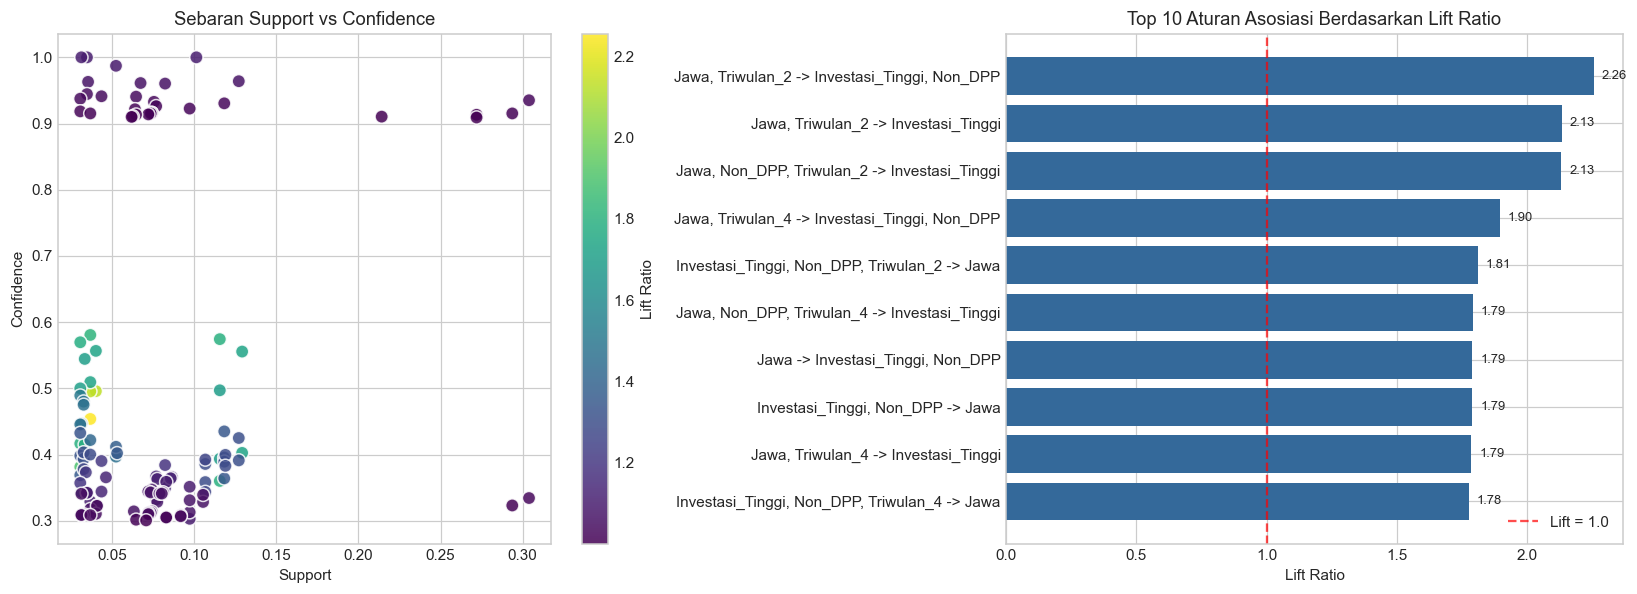

In [5]:
min_conf = 0.30

rules = association_rules(freq_fpgrowth, metric='confidence', min_threshold=min_conf)
rules_valid = rules[rules['lift'] > 1.0].sort_values(by=['lift', 'confidence'], ascending=False).copy()

rules_valid['antecedent_str'] = rules_valid['antecedents'].apply(lambda x: ', '.join(sorted(list(x))))
rules_valid['consequent_str'] = rules_valid['consequents'].apply(lambda x: ', '.join(sorted(list(x))))
rules_valid['aturan'] = 'IF {' + rules_valid['antecedent_str'] + '} THEN {' + rules_valid['consequent_str'] + '}'

print(f'Total aturan valid (Lift > 1.0): {len(rules_valid)} aturan')
display(rules_valid[['aturan', 'support', 'confidence', 'lift', 'leverage', 'conviction']].head(15).style.format({
    'support': '{:.4f}',
    'confidence': '{:.4f}',
    'lift': '{:.4f}',
    'leverage': '{:.4f}',
    'conviction': '{:.4f}'
}))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sc = axes[0].scatter(
    rules_valid['support'],
    rules_valid['confidence'],
    c=rules_valid['lift'],
    cmap='viridis',
    s=75,
    alpha=0.85,
    edgecolors='white'
)
cbar = fig.colorbar(sc, ax=axes[0])
cbar.set_label('Lift Ratio')
axes[0].set_title('Sebaran Support vs Confidence')
axes[0].set_xlabel('Support')
axes[0].set_ylabel('Confidence')

top10 = rules_valid.head(10).copy()
top10['label'] = top10['antecedent_str'] + ' -> ' + top10['consequent_str']

axes[1].barh(top10['label'][::-1], top10['lift'][::-1], color='#34699a')
axes[1].axvline(x=1.0, color='red', linestyle='--', alpha=0.7, label='Lift = 1.0')
axes[1].set_title('Top 10 Aturan Asosiasi Berdasarkan Lift Ratio')
axes[1].set_xlabel('Lift Ratio')
axes[1].legend(loc='lower right')

for idx, val in enumerate(top10['lift'][::-1]):
    axes[1].text(val + 0.03, idx, f'{val:.2f}', va='center', fontsize=8.5)

plt.tight_layout()
plt.show()


## 6. Analisis Khusus Destinasi Pariwisata Prioritas (DPP)

Pemodelan khusus pada 134 data kawasan DPP (`min_support = 0.04`, `min_confidence = 0.40`) untuk melihat destinasi mana yang paling kuat menarik investasi tinggi.

In [6]:
df_dpp = df[df['DPP'] != ''].copy()
df_dpp['DPP_Destinasi'] = 'DPP_' + df_dpp['DPP'].str.replace(' - ', '_').str.replace(' ', '_')

df_dpp_enc = pd.get_dummies(
    df_dpp[['Waktu_Triwulan', 'DPP_Destinasi', 'Tingkat_Investasi']],
    prefix='',
    prefix_sep=''
).astype(bool)

freq_dpp = fpgrowth(df_dpp_enc, min_support=0.04, use_colnames=True)
rules_dpp = association_rules(freq_dpp, metric='confidence', min_threshold=0.40)
rules_dpp_valid = rules_dpp[rules_dpp['lift'] > 1.0].sort_values('lift', ascending=False).copy()

rules_dpp_valid['aturan'] = (
    'IF {' + rules_dpp_valid['antecedents'].apply(lambda x: ', '.join(sorted(list(x)))) +
    '} THEN {' + rules_dpp_valid['consequents'].apply(lambda x: ', '.join(sorted(list(x)))) + '}'
)

print(f'Jumlah data DPP: {len(df_dpp)} baris | Aturan valid: {len(rules_dpp_valid)} aturan')
display(rules_dpp_valid[['aturan', 'support', 'confidence', 'lift']].head(10).style.format({
    'support': '{:.4f}',
    'confidence': '{:.4f}',
    'lift': '{:.4f}'
}))


Jumlah data DPP: 134 baris | Aturan valid: 11 aturan


,aturan,support,confidence,lift
4,IF {DPP_Lombok_Gili_Tramena} THEN {Investasi_Tinggi},0.0970,0.6500,1.8935
5,IF {DPP_Danau_Toba} THEN {Investasi_Rendah},0.0597,0.4211,1.8200
10,IF {DPP_Bangka_Belitung} THEN {Investasi_Sedang},0.1045,0.6667,1.7867
1,IF {Investasi_Rendah} THEN {Triwulan_3},0.0970,0.4194,1.7028
8,IF {DPP_Bromo_Tengger_Semeru} THEN {Investasi_Tinggi},0.0821,0.5500,1.6022
3,IF {DPP_Manado_Likupang} THEN {Investasi_Sedang},0.0746,0.5000,1.3400
9,IF {DPP_Borobudur_Yogya_Prambananan} THEN {Investasi_Tinggi},0.0672,0.4500,1.3109
2,IF {Triwulan_4} THEN {Investasi_Sedang},0.1119,0.4839,1.2968
0,IF {Triwulan_2} THEN {Investasi_Sedang},0.1343,0.4737,1.2695
6,IF {DPP_Danau_Toba} THEN {Investasi_Sedang},0.0672,0.4737,1.2695


## 7. Perbandingan Waktu Komputasi Apriori vs FP-Growth

Pengujian waktu eksekusi dilakukan sebanyak 5 kali pengulangan pada matriks transaksi `1.471 x 16` untuk melihat rata-rata kecepatan masing-masing algoritma.

,Parameter,Apriori,FP-Growth
0,Pendekatan Algoritma,Level-wise (Breadth-First),Divide-and-Conquer (FP-Tree)
1,Pembangkitan Kandidat,Ya (membentuk kandidat Ck),Tidak ada
2,Jumlah Pindaian Data,Beberapa kali sesuai panjang itemset,2 kali pemindaian
3,Jumlah Frequent Itemset,110 itemset,110 itemset
4,Rata-rata Waktu Eksekusi (ms),2.659 ms,6.492 ms


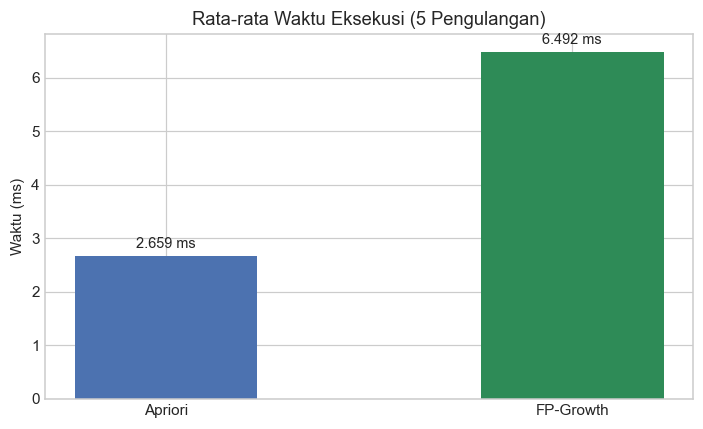

In [7]:
iterations = 5
time_ap, time_fp = [], []

for _ in range(iterations):
    t0 = time.perf_counter()
    apriori(df_encoded, min_support=min_sup, use_colnames=True)
    time_ap.append((time.perf_counter() - t0) * 1000)

    t0 = time.perf_counter()
    fpgrowth(df_encoded, min_support=min_sup, use_colnames=True)
    time_fp.append((time.perf_counter() - t0) * 1000)

avg_ap = np.mean(time_ap)
avg_fp = np.mean(time_fp)

komparasi = pd.DataFrame({
    'Parameter': [
        'Pendekatan Algoritma',
        'Pembangkitan Kandidat',
        'Jumlah Pindaian Data',
        'Jumlah Frequent Itemset',
        'Rata-rata Waktu Eksekusi (ms)'
    ],
    'Apriori': [
        'Level-wise (Breadth-First)',
        'Ya (membentuk kandidat Ck)',
        'Beberapa kali sesuai panjang itemset',
        f'{len(freq_apriori)} itemset',
        f'{avg_ap:.3f} ms'
    ],
    'FP-Growth': [
        'Divide-and-Conquer (FP-Tree)',
        'Tidak ada',
        '2 kali pemindaian',
        f'{len(freq_fpgrowth)} itemset',
        f'{avg_fp:.3f} ms'
    ]
})

display(komparasi)

plt.figure(figsize=(6.5, 4))
bars = plt.bar(['Apriori', 'FP-Growth'], [avg_ap, avg_fp], color=['#4c72b0', '#2e8b57'], width=0.45)
plt.title('Rata-rata Waktu Eksekusi (5 Pengulangan)')
plt.ylabel('Waktu (ms)')
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.15, f'{b.get_height():.3f} ms', ha='center', fontsize=9.5)
plt.tight_layout()
plt.show()


## 8. Ekspor Model dan Hasil Aturan untuk Dashboard

Menyimpan hasil 25 aturan teratas ke `mined_rules.json` (untuk integrasi web ParekrafMind) dan menyimpan bundel model ke `parekrafmind_model.pkl`.

In [8]:
top_rules_json = []
for _, row in rules_valid.head(25).iterrows():
    top_rules_json.append({
        'antecedents': sorted(list(row['antecedents'])),
        'consequents': sorted(list(row['consequents'])),
        'support': round(float(row['support']), 4),
        'confidence': round(float(row['confidence']), 4),
        'lift': round(float(row['lift']), 4),
        'leverage': round(float(row['leverage']), 4),
        'conviction': round(float(row['conviction']), 4) if np.isfinite(row['conviction']) else None
    })

with open('mined_rules.json', 'w', encoding='utf-8') as f:
    json.dump(top_rules_json, f, indent=2)

model_bundle = {
    'project': 'ParekrafMind: Smart Tourism Investment Intelligence for Creative Economy Growth',
    'params': {'min_support': min_sup, 'min_confidence': min_conf},
    'frequent_itemsets': freq_fpgrowth,
    'rules_valid': rules_valid[['antecedents', 'consequents', 'support', 'confidence', 'lift', 'leverage', 'conviction']],
    'rules_dpp': rules_dpp_valid[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
}

with open('parekrafmind_model.pkl', 'wb') as f:
    pickle.dump(model_bundle, f)

print('Berhasil menyimpan mined_rules.json dan parekrafmind_model.pkl')


Berhasil menyimpan mined_rules.json dan parekrafmind_model.pkl


## 9. Ringkasan

- **Konsistensi hasil:** Apriori dan FP-Growth menghasilkan 110 *frequent itemset* yang identik, dengan 131 aturan asosiasi valid (`Lift > 1,0`).
- **Temuan utama:** Investasi tinggi (> Rp 10 miliar) masih banyak terpusat di Pulau Jawa non-DPP pada Triwulan 2 dan 4 (Lift hingga 2,26). Pada subset kawasan prioritas, DPP Lombok-Gili Tramena (Confidence 65%) dan Bromo-Tengger-Semeru (Confidence 55%) memiliki keterkaitan kuat dengan investasi tinggi, sedangkan investasi nol lebih sering muncul di wilayah non-DPP luar Jawa seperti sebagian Sumatera (Lift 1,46).
- **Kinerja algoritma:** Pada data berdimensi kecil (`1.471 x 16`), vektorisasi array Apriori di `mlxtend` bisa sedikit lebih cepat dibanding proses pembuatan pohon FP-Tree di memori, sementara keunggulan FP-Growth akan lebih terasa saat variasi item jauh lebih banyak dan *sparse*.
